# Why motorbike couriers miss orders, and what it costs them
**Bolt Send × eWAKA · revised analysis (after the SCU MSBA Analytics Showdown, Fall 2026)**

**Question:** What is the biggest reason motorbike couriers fail to complete orders, and how much more would a courier earn per day if it were reduced?

This notebook is a revised version of Team 7's competition analysis. After judging, the judges' questions exposed three problems, which are corrected here:
1. The "too many orders at once" load measure counted missed offers as busy time. Counting only answered offers, busyness explains little of the rise.
2. The mid-trip flag reset after any unfinished order. Fixed, mid-trip offers are 25.5% of motorbike misses, not 13.7%.
3. The staffing gap ("28 of 74 courier-hours") mixed units. The fair comparison is 37 needed vs 28 online.

**Data:** two Excel files provided by eWAKA for the competition (`boltsend_rider_history.xlsx`, `boltsend_rider_perfomance.xlsx`). They are **not included** in this repository. Place them in `data/` to re-run; saved outputs can be read without running.

**Main comparison:** bicycles May–Aug 2025 vs motorbikes May–Aug 2026, optional rides excluded.

## Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

TEAL, ORANGE, RED, GREEN, GRAY, LIGHT = '#1B7A83', '#D4690F', '#B5392F', '#1F7A4D', '#6B7B74', '#C9D3CE'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})

hist = pd.read_excel('../data/boltsend_rider_history.xlsx')
perf = pd.read_excel('../data/boltsend_rider_perfomance.xlsx')

hist['dt'] = pd.to_datetime(hist['date'].str[:19])                 # local Nairobi time
hist['day'] = hist['dt'].dt.normalize()
hist['moto'] = hist['vehicle_model'].isin(['eWAKA Jasiri', 'RhingGo M300'])
perf['day'] = pd.to_datetime(perf['report_date'])

NR, FIN, REJ = 'Driver did not respond', 'Finished', 'Driver rejected'
CUST = ['Rider cancelled', 'Rider did not show']                     # 'Rider' = customer in this data
N_DAYS = 123                                                         # May 1 - Aug 31

orders = hist[hist['optional_ride'].isna()].sort_values(['individual_identifier', 'dt']).copy()
orders['nr'] = orders['status'] == NR
g = orders.groupby('individual_identifier')

# Mid-trip flag (corrected): the courier's latest trip end so far, carried forward past
# orders that never finished. The original version did not carry it forward, so the flag
# reset after any cancelled or missed order.
orders['fin_end'] = pd.to_datetime(orders['fare_finalised'].str[:19], errors='coerce')
orders['busy_until'] = g['fin_end'].transform(lambda s: s.shift(1).cummax().ffill())
orders['mid_trip'] = orders['busy_until'] > orders['dt']

bike = orders[~orders['moto'] & (orders['dt'] >= '2025-05-01') & (orders['dt'] < '2025-09-01')].copy()
moto = orders[orders['moto'] & (orders['dt'] >= '2026-05-01') & (orders['dt'] < '2026-09-01')].copy()
print(f"Bicycles May-Aug 2025:  {len(bike):,} orders, {bike['individual_identifier'].nunique()} couriers")
print(f"Motorbikes May-Aug 2026: {len(moto):,} orders, {moto['individual_identifier'].nunique()} couriers")

def finished_per_online_hour(df, start, end):
    p = perf[perf['individual_identifier'].isin(df['individual_identifier'].unique()) & (perf['day'] >= start) & (perf['day'] < end)]
    return p['finished_rides'].sum() / (p['online_time_min'].sum() / 60)
print(f"\nFinished orders per online hour: bicycle {finished_per_online_hour(bike, '2025-05-01', '2025-09-01'):.2f} "
      f"vs motorbike {finished_per_online_hour(moto, '2026-05-01', '2026-09-01'):.2f}")
print(f"Completion rate: bicycle {(bike['status'] == FIN).mean():.1%} vs motorbike {(moto['status'] == FIN).mean():.1%}")

Bicycles May-Aug 2025:  45,947 orders, 213 couriers
Motorbikes May-Aug 2026: 9,086 orders, 21 couriers

Finished orders per online hour: bicycle 0.73 vs motorbike 1.50
Completion rate: bicycle 59.2% vs motorbike 56.0%


## 1. Where orders are lost: couriers not answering
Out of every 100 orders, the outcome that changed most is **courier didn't answer**. Once a courier accepts, motorbikes finish *more* orders than bicycles did.

                                  Bicycle 2025  Motorbike 2026  Change (pts)
status                                                                      
Finished                                  59.2            56.0          -3.2
Customer cancelled / no-show              27.9            25.4          -2.5
Courier didn't answer                      6.9            14.0           7.1
Courier accepted, then cancelled           4.9             2.4          -2.5
Courier rejected                           0.9             2.1           1.2

Finished once the courier accepted: bicycle 64.3% vs motorbike 66.8%


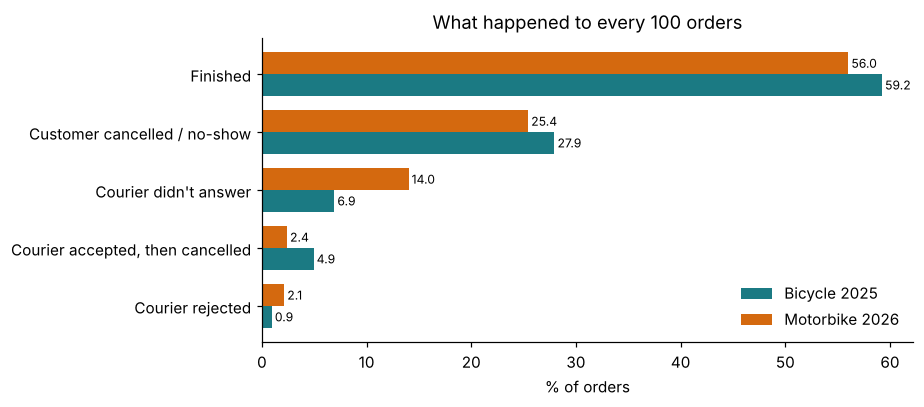

In [2]:
labels = {FIN: 'Finished', 'Rider cancelled': 'Customer cancelled / no-show', 'Rider did not show': 'Customer cancelled / no-show',
          NR: "Courier didn't answer", 'Driver cancelled': 'Courier accepted, then cancelled', REJ: 'Courier rejected'}
order = ['Finished', 'Customer cancelled / no-show', "Courier didn't answer", 'Courier accepted, then cancelled', 'Courier rejected']
mix = pd.DataFrame({name: df['status'].map(labels).value_counts(normalize=True) * 100
                    for name, df in [('Bicycle 2025', bike), ('Motorbike 2026', moto)]}).loc[order]
mix['Change (pts)'] = mix['Motorbike 2026'] - mix['Bicycle 2025']
print(mix.round(1).to_string())

def finish_after_accept(df):
    return (df.loc[~df['status'].isin([NR, REJ]), 'status'] == FIN).mean()
print(f"\nFinished once the courier accepted: bicycle {finish_after_accept(bike):.1%} vs motorbike {finish_after_accept(moto):.1%}")

ax = mix[['Bicycle 2025', 'Motorbike 2026']].iloc[::-1].plot.barh(color=[TEAL, ORANGE], figsize=(8.5, 3.8), width=0.75)
ax.set(title='What happened to every 100 orders', xlabel='% of orders', ylabel='')
ax.legend(frameon=False)
for c in ax.containers: ax.bar_label(c, fmt='%.1f', fontsize=8, padding=2)
plt.tight_layout(); plt.show()

**Note.** Customer cancellations and no-shows are the largest non-finished group (about a quarter of orders), but they did not rise and couriers cannot control them. Among outcomes couriers control, **no response is the biggest and the one that doubled (6.9% → 14.0%)**.

## 2. Is it because couriers are too busy? Mostly no
Bolt re-sends offers to a courier who has just missed one, so counting every offer makes busy hours look busier because of the misses themselves. Here load counts only the offers a courier **answered** in the 60 minutes before each new offer.

In [3]:
def answered_last_hour(df):
    t = df['dt'].values.astype('datetime64[s]').astype(np.int64)
    answered = np.concatenate([[0], np.cumsum((~df['nr']).values.astype(int))])
    start = np.searchsorted(t, t - 3600, side='left')
    return pd.Series(answered[np.arange(len(t))] - answered[start], index=df.index)

moto['answered_60'] = moto.groupby('individual_identifier', group_keys=False).apply(answered_last_hour).clip(upper=3)
load = moto.groupby('answered_60')['nr'].agg(offers='size', no_response='mean')
load.index = ['0', '1', '2', '3 or more']
load['no_response'] *= 100
print(load.round(1).to_string())
print(f"\nLeast busy -> busiest: {load['no_response'].iloc[0]:.1f}% -> {load['no_response'].iloc[-1]:.1f}% "
      f"(+{load['no_response'].iloc[-1] - load['no_response'].iloc[0]:.1f} pts)")

           offers  no_response
0            1892         12.7
1            2631         13.1
2            2137         14.0
3 or more    2426         16.0

Least busy -> busiest: 12.7% -> 16.0% (+3.3 pts)


Busyness adds only about 3 points. The rise from 6.9% to 14.0% is twice that, so something else is driving it.

## 3. Three patterns explain the rise, in roughly equal parts
Every offer is put in one group, in this order:
1. **Mid-trip:** the offer arrives while the courier is still on an earlier trip.
2. **Repeat miss:** not mid-trip, and the courier missed another offer in the previous 10 minutes.
3. **Other:** an ordinary offer to a free courier who hasn't just missed one.

Each group's contribution = missed offers in that group ÷ all offers. The three contributions add up to the overall no-response rate.

No-response rate split by pattern (percentage points of all offers)
             Bicycle 2025  Motorbike 2026  Rise (pts)  Share of rise
pattern                                                             
Mid-trip              1.3             3.6         2.2           31.6
Repeat miss           0.5             3.5         3.0           41.7
Other                 5.1             7.0         1.9           26.7
Total                 6.9            14.0         7.1          100.0

Share of motorbike misses by pattern: Mid-trip 25.5%, Repeat miss 24.7%, Other 49.9%
Motorbike miss rate within each pattern: Mid-trip 30.4%, Repeat miss 34.4%, Other 8.9%


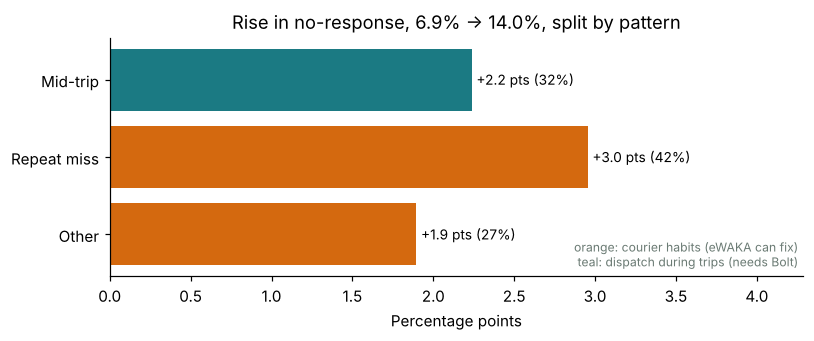

In [4]:
for df in (bike, moto):
    last_miss = df['dt'].where(df['nr']).groupby(df['individual_identifier']).transform(lambda s: s.shift(1).ffill())
    since_miss = (df['dt'] - last_miss).dt.total_seconds() / 60
    df['pattern'] = np.select([df['mid_trip'], since_miss <= 10], ['Mid-trip', 'Repeat miss'], 'Other')

PATTERNS = ['Mid-trip', 'Repeat miss', 'Other']
contrib = pd.DataFrame({name: df.groupby('pattern')['nr'].sum().reindex(PATTERNS) / len(df) * 100
                        for name, df in [('Bicycle 2025', bike), ('Motorbike 2026', moto)]})
contrib['Rise (pts)'] = contrib['Motorbike 2026'] - contrib['Bicycle 2025']
contrib['Share of rise'] = contrib['Rise (pts)'] / contrib['Rise (pts)'].sum() * 100
contrib.loc['Total'] = contrib.sum()
contrib.loc['Total', 'Share of rise'] = 100
print('No-response rate split by pattern (percentage points of all offers)')
print(contrib.round(1).to_string())

share_nr = moto.loc[moto['nr'], 'pattern'].value_counts(normalize=True).reindex(PATTERNS) * 100
print('\nShare of motorbike misses by pattern:', ', '.join(f"{k} {v:.1f}%" for k, v in share_nr.items()))
rate = moto.groupby('pattern')['nr'].mean().reindex(PATTERNS) * 100
print('Motorbike miss rate within each pattern:', ', '.join(f"{k} {v:.1f}%" for k, v in rate.items()))

rise = contrib.loc[PATTERNS, 'Rise (pts)']
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bars = ax.barh(PATTERNS[::-1], rise[::-1], color=[ORANGE, ORANGE, TEAL])   # orange: eWAKA can fix; teal: needs Bolt
ax.bar_label(bars, labels=[f"+{v:.1f} pts ({v / rise.sum():.0%})" for v in rise[::-1]], padding=3, fontsize=9)
ax.set(title='Rise in no-response, 6.9% → 14.0%, split by pattern', xlabel='Percentage points', xlim=(0, rise.max() * 1.45))
ax.text(rise.max() * 1.44, -0.45, 'orange: courier habits (eWAKA can fix)\nteal: dispatch during trips (needs Bolt)',
        ha='right', va='bottom', fontsize=8, color=GRAY)
plt.tight_layout(); plt.show()

- **Mid-trip** offers are missed about 3 times in 10, and make up a quarter of motorbike misses. Whether a courier gets offers during a trip is Bolt's dispatch choice.
- **Repeat misses** are the biggest part of the rise. After a miss, Bolt often sends another offer within two minutes (below), and that one is often missed too.
- **Other** misses rose as well. These are free couriers simply not answering.

Repeat misses and other misses (about two-thirds of the rise) are about courier habits, which eWAKA can change on its own.

In [5]:
def after_miss(df):
    d = df.sort_values(['individual_identifier', 'dt'])
    nxt_dt = d.groupby('individual_identifier')['dt'].shift(-1)
    nxt_nr = d.groupby('individual_identifier')['nr'].shift(-1)
    gap = (nxt_dt - d['dt']).dt.total_seconds() / 60
    miss = d['nr']
    return pd.Series({'next offer within 2 min (%)': (gap[miss] <= 2).mean() * 100,
                      'that next offer also missed (%)': nxt_nr[miss & (gap <= 2)].astype(float).mean() * 100})
print(pd.DataFrame({'Bicycle 2025': after_miss(bike), 'Motorbike 2026': after_miss(moto)}).round(1).to_string())

                                 Bicycle 2025  Motorbike 2026
next offer within 2 min (%)              10.6            49.4
that next offer also missed (%)          35.7            48.8


## 4. What missed orders cost a courier
Income here is gross: fare plus tips on finished orders, before Bolt's commission and eWAKA's deductions (not in the data).

In [6]:
moto['earn'] = (moto['trip_priceksh'] + moto['rider_tipsksh']).where(moto['status'] == FIN, 0)
e = moto.groupby(['individual_identifier', 'day']).agg(earn=('earn', 'sum'), misses=('nr', 'sum')).reset_index()
e = e.merge(perf[['individual_identifier', 'day', 'online_time_min']], on=['individual_identifier', 'day'])
e = e[e['online_time_min'] >= 60]                                   # courier-days with 1+ online hour
median_day = e['earn'].median()
fare = moto.loc[moto['status'] == FIN, 'trip_priceksh']
value_per_offer = finish_after_accept(moto) * fare.median()         # expected fare an answered offer brings
print(f"Typical courier-day: KSh {median_day:,.0f} over {(e['online_time_min'] / 60).median():.1f} online hours")
print(f"Missed offers per courier-day: {e['misses'].mean():.1f}, worth about KSh {value_per_offer:.0f} each "
      f"-> {e['misses'].mean() * value_per_offer / median_day:.0%} of daily income")

# If no-response and rejections returned to the 2025 bicycle level, and accepted orders
# kept finishing at today's motorbike rate:
accept_2025 = 1 - bike['status'].isin([NR, REJ]).mean()
now, target = (moto['status'] == FIN).mean(), accept_2025 * finish_after_accept(moto)
offers_per_day = moto.groupby(['individual_identifier', 'day']).size().mean()
extra = offers_per_day * (target - now)
print(f"\nCompletion: {now:.1%} now -> {target:.1%} with misses back at 2025 levels")
print(f"Per courier-day: +{extra:.1f} finished orders x KSh {fare.mean():.0f} average fare = +KSh {extra * fare.mean():.0f} "
      f"(about +{extra * fare.mean() / median_day:.0%} of a typical day)")

# Cost of paying couriers KSh 100 per customer no-show (couriers get KSh 0 today)
no_shows = (moto['status'] == 'Rider did not show').sum()
print(f"\nCustomer no-shows May-Aug 2026: {no_shows}; at KSh 100 each = KSh {no_shows * 100:,} "
      f"= {no_shows * 100 / fare.sum():.1%} of KSh {fare.sum():,.0f} in fares")

Typical courier-day: KSh 1,860 over 6.3 online hours
Missed offers per courier-day: 2.3, worth about KSh 114 each -> 14% of daily income

Completion: 56.0% now -> 61.6% with misses back at 2025 levels
Per courier-day: +0.9 finished orders x KSh 204 average fare = +KSh 182 (about +10% of a typical day)

Customer no-shows May-Aug 2026: 190; at KSh 100 each = KSh 19,000 = 1.8% of KSh 1,036,860 in fares


## 5. Are there enough couriers? A small gap, not 2.6×
Demand counts orders couriers could actually have finished: non-optional offers, excluding customer cancellations and no-shows. Capacity is finished orders per online hour.

In [7]:
p = perf[perf['individual_identifier'].isin(moto['individual_identifier'].unique())
         & (perf['day'] >= '2026-05-01') & (perf['day'] < '2026-09-01')]
online_per_day = p['online_time_min'].sum() / 60 / N_DAYS
capacity = p['finished_rides'].sum() / (p['online_time_min'].sum() / 60)
doable = moto[~moto['status'].isin(CUST)]
doable_per_day = len(doable) / N_DAYS
need = doable_per_day / capacity
print(f"Orders couriers could have finished: {doable_per_day:.0f} a day")
print(f"Capacity: {capacity:.2f} finished orders per online hour -> {need:.0f} courier-hours needed")
print(f"Online: {online_per_day:.0f} courier-hours a day -> gap of about {need - online_per_day:.0f} hours ({need / online_per_day:.1f}x)")
print(f"Share of these orders arriving 12:00-17:59: {doable['dt'].dt.hour.between(12, 17).mean():.0%}")
print("\nThe original '28 of 74' divided all offers (incl. optional rides) by a finished-order capacity; it is withdrawn.")

Orders couriers could have finished: 55 a day
Capacity: 1.50 finished orders per online hour -> 37 courier-hours needed
Online: 28 courier-hours a day -> gap of about 9 hours (1.3x)
Share of these orders arriving 12:00-17:59: 43%

The original '28 of 74' divided all offers (incl. optional rides) by a finished-order capacity; it is withdrawn.


The gap is real but modest (about 9 courier-hours a day), and it is an upper bound: capacity of 1.5 orders per hour already includes idle time and missed offers, so better answering alone may close part of it. 12:00–18:00 is the busiest stretch of the day, so any extra courier time belongs there.

## 6. A courier performance score
A simple score Bolt Send or eWAKA could track weekly:

**Courier Performance Score = Reliability × Productivity**
- **Reliability** = 1 − (no responses + rejections + courier cancellations) ÷ offers. Only what the courier controls.
- **Productivity** = finished orders per online hour ÷ fleet median (capped at 1.25).

Multiplying stops "fake" work: a courier can't score well by staying online and ignoring offers. Couriers are shown with anonymous labels.

In [8]:
c = moto.groupby('individual_identifier').agg(offers=('status', 'size'),
        kept=('status', lambda s: 1 - s.isin([NR, REJ, 'Driver cancelled']).mean()),
        finished=('status', lambda s: (s == FIN).sum()))
c = c.join(p.groupby('individual_identifier')['online_time_min'].sum() / 60).rename(columns={'online_time_min': 'online_h'})
c = c[(c['offers'] >= 50) & (c['online_h'] > 0)]
c['per_hour'] = c['finished'] / c['online_h']
c['productivity'] = (c['per_hour'] / c['per_hour'].median()).clip(upper=1.25)
c['score'] = c['kept'] * c['productivity']
c = c.sort_values('score', ascending=False)
c.index = [f"Courier {i:02d}" for i in range(1, len(c) + 1)]
print(f"Fleet median: {c['per_hour'].median():.2f} finished orders per online hour ({len(c)} couriers with 50+ offers)\n")
print(c[['offers', 'kept', 'per_hour', 'productivity', 'score']].round(2).to_string())

Fleet median: 1.33 finished orders per online hour (20 couriers with 50+ offers)

            offers  kept  per_hour  productivity  score
Courier 01     264  0.90      1.92          1.25   1.13
Courier 02    1046  0.90      2.01          1.25   1.13
Courier 03     401  0.89      1.71          1.25   1.12
Courier 04     209  0.87      1.73          1.25   1.09
Courier 05    1268  0.89      1.60          1.20   1.07
Courier 06    1351  0.84      1.60          1.21   1.01
Courier 07     155  0.96      1.32          1.00   0.96
Courier 08     753  0.74      1.74          1.25   0.92
Courier 09     604  0.74      1.59          1.20   0.88
Courier 10     910  0.81      1.33          1.00   0.81
Courier 11     329  0.84      1.28          0.96   0.81
Courier 12     359  0.83      1.27          0.96   0.80
Courier 13     306  0.82      1.29          0.97   0.80
Courier 14     340  0.68      1.44          1.09   0.74
Courier 15     102  0.60      1.24          0.93   0.56
Courier 16     175  0.

## Summary
- **Biggest courier-side reason orders fail:** couriers not answering offers, up from 6.9% to 14.0%.
- **Not mainly busyness** (+3 pts). The rise splits into mid-trip offers, repeat misses right after a miss, and ordinary misses by free couriers, in roughly equal parts.
- **Cost:** about 2 missed offers a day, roughly 14% of a courier's daily income. Back at 2025 levels: about +1 order and +KSh 180 a day (about +10%).
- **Fix order:** (1) "answer it or turn it off" coaching, covering about two-thirds of the rise, which eWAKA can start alone; (2) ask Bolt to stop offers during trips; (3) pay couriers for customer no-shows; add 1–2 afternoon couriers only if a gap remains after a few weeks (about 37 courier-hours needed a day vs 28 online).

**Limitations:** different years for bicycles and motorbikes; 21 motorbike couriers; no order IDs (re-sent offers can't be linked); no app status or location data, so trip times are inferred; income is gross.